# ¿Cuántos menores irían a clase a oscuras con el horario de verano permanente?

**Categoría: EDA (análisis exploratorio de datos)**

En este cuaderno comparo tres relojes para España durante el curso 2026-2027: el sistema estacional actual, el horario de invierno permanente y el horario de verano permanente. No genero una predicción. Calculo cuántas mañanas escolares empezarían antes del amanecer para la población de 5 a 17 años de cada municipio.

## Ruta de lectura

1. preparo la población municipal y compruebo su cobertura;
2. calculo el amanecer local con un algoritmo astronómico reproducible;
3. construyo un calendario escolar común y explícito;
4. comparo tres horas de salida de casa;
5. mido la diferencia territorial y la sensibilidad del resultado;
6. cierro con las limitaciones.

## Glosario breve

- **Mañana oscura:** la salida de casa ocurre antes del amanecer oficial.
- **Menor-día:** un menor expuesto durante una mañana. Diez menores durante dos mañanas suman veinte menor-días.
- **Horario de invierno permanente:** UTC+1 en la Península y Baleares; UTC+0 en Canarias.
- **Horario de verano permanente:** UTC+2 en la Península y Baleares; UTC+1 en Canarias.


## 1. Fuentes y unidad de análisis

Uso la población de 5 a 17 años del **Censo anual de población 2025 del INE**, tabla nacional 68542, por municipio y edad simple. Cada fila procesada representa un municipio. Para ubicarlo empleo los centroides municipales publicados por el **Instituto Geográfico Nacional (IGN)**.

La población en edad escolar no equivale exactamente al alumnado matriculado: puede incluir menores no escolarizados y no identifica dónde estudian. La utilizo porque ofrece una cobertura nacional homogénea y evita repartir matrículas autonómicas entre centros de manera arbitraria.


In [1]:
# importo las librerías y fijo las rutas del proyecto
from pathlib import Path
from datetime import date, datetime, time, timedelta, timezone
from zoneinfo import ZoneInfo
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

color_principal = "#446ddf"
ruta_proyecto = Path.cwd()
ruta_brutos = ruta_proyecto / "datos_brutos"
ruta_procesados = ruta_proyecto / "datos_procesados"
ruta_resultados = ruta_proyecto / "resultados"
ruta_graficos = ruta_proyecto / "graficos"

for ruta in (ruta_procesados, ruta_resultados, ruta_graficos):
    ruta.mkdir(exist_ok=True)


### Preparo la población de 5 a 17 años

La descarga del INE contiene una fila por combinación de territorio, sexo, edad y año. Conservo municipios, ambos sexos, edades simples de 5 a 17 años y el valor definitivo de 2025. Después sumo las trece edades. Leo el archivo por bloques porque la descarga nacional supera los 450 MB.


In [2]:
# leo la descarga nacional por bloques y filtro antes de acumular
ruta_ine = ruta_brutos / "ine_68542_poblacion_municipio_edad.csv"
bloques_filtrados = []

for bloque in pd.read_csv(ruta_ine, sep="\t", encoding="utf-8", dtype=str, chunksize=250_000):
    edad_numerica = pd.to_numeric(bloque["Edad"].str.extract(r"^(\d+)", expand=False), errors="coerce")
    filtro = (
        bloque["Municipios"].notna()
        & (bloque["Sexo"] == "Total")
        & edad_numerica.between(5, 17)
        & (bloque["Periodo"] == "2025")
    )
    bloques_filtrados.append(bloque.loc[filtro, ["Municipios", "Edad", "Total"]].copy())

poblacion_edades = pd.concat(bloques_filtrados, ignore_index=True)
poblacion_edades["codigo_ine"] = poblacion_edades["Municipios"].str[:5]
poblacion_edades["municipio_ine"] = poblacion_edades["Municipios"].str[6:]
poblacion_edades["edad"] = poblacion_edades["Edad"].str.extract(r"(\d+)").astype(int)
poblacion_edades["poblacion"] = pd.to_numeric(
    poblacion_edades["Total"].str.replace(".", "", regex=False), errors="coerce"
).fillna(0)
poblacion_municipal = (
    poblacion_edades.groupby(["codigo_ine", "municipio_ine"], as_index=False)["poblacion"]
    .sum()
    .rename(columns={"poblacion": "poblacion_5_17"})
)

len(poblacion_municipal), int(poblacion_municipal["poblacion_5_17"].sum())


(8132, 6248677)

### Añado las coordenadas oficiales

Cruzo ambos archivos mediante el código municipal del INE. Compruebo cuántos municipios y menores quedan fuera antes de continuar.


In [3]:
# convierto los centroides del IGN en una tabla y los uno por código oficial
with open(ruta_brutos / "ign_centroides_municipios.geojson", encoding="utf-8") as archivo:
    geojson_ign = json.load(archivo)

filas_ign = []
for elemento in geojson_ign["features"]:
    propiedades = elemento["properties"]
    filas_ign.append({
        "codigo_ine": str(propiedades["codine"]).zfill(5),
        "municipio_ign": propiedades["nombre"],
        "provincia": propiedades["provincia"],
        "latitud": float(propiedades["latitud"]),
        "longitud": float(propiedades["longitud"]),
    })

coordenadas = pd.DataFrame(filas_ign).drop_duplicates("codigo_ine")
municipios = poblacion_municipal.merge(coordenadas, on="codigo_ine", how="left", validate="one_to_one")

cobertura = pd.Series({
    "municipios_ine": len(poblacion_municipal),
    "municipios_con_coordenadas": int(municipios["latitud"].notna().sum()),
    "menores_sin_coordenadas": int(municipios.loc[municipios["latitud"].isna(), "poblacion_5_17"].sum()),
})
cobertura


municipios_ine                8132
municipios_con_coordenadas    8131
menores_sin_coordenadas        623
dtype: int64

In [4]:
# asigno cada provincia a su comunidad autónoma para resumir el mapa
comunidad_por_provincia = {
    "01":"País Vasco", "02":"Castilla-La Mancha", "03":"Comunitat Valenciana",
    "04":"Andalucía", "05":"Castilla y León", "06":"Extremadura", "07":"Illes Balears",
    "08":"Cataluña", "09":"Castilla y León", "10":"Extremadura", "11":"Andalucía",
    "12":"Comunitat Valenciana", "13":"Castilla-La Mancha", "14":"Andalucía", "15":"Galicia",
    "16":"Castilla-La Mancha", "17":"Cataluña", "18":"Andalucía", "19":"Castilla-La Mancha",
    "20":"País Vasco", "21":"Andalucía", "22":"Aragón", "23":"Andalucía", "24":"Castilla y León",
    "25":"Cataluña", "26":"La Rioja", "27":"Galicia", "28":"Comunidad de Madrid",
    "29":"Andalucía", "30":"Región de Murcia", "31":"Comunidad Foral de Navarra",
    "32":"Galicia", "33":"Principado de Asturias", "34":"Castilla y León", "35":"Canarias",
    "36":"Galicia", "37":"Castilla y León", "38":"Canarias", "39":"Cantabria",
    "40":"Castilla y León", "41":"Andalucía", "42":"Castilla y León", "43":"Cataluña",
    "44":"Aragón", "45":"Castilla-La Mancha", "46":"Comunitat Valenciana", "47":"Castilla y León",
    "48":"País Vasco", "49":"Castilla y León", "50":"Aragón", "51":"Ceuta", "52":"Melilla",
}
municipios["comunidad"] = municipios["codigo_ine"].str[:2].map(comunidad_por_provincia)
municipios["es_canarias"] = municipios["codigo_ine"].str[:2].isin(["35", "38"])
municipios.to_csv(ruta_procesados / "municipios_poblacion_5_17.csv", index=False)


## 2. Calculo el amanecer

Aplico las ecuaciones solares publicadas por NOAA. El cálculo devuelve el amanecer en UTC para una fecha, latitud y longitud. Después lo convierto al reloj de cada escenario. Uso el centroide municipal: describe bien el municipio medio, aunque en términos muy extensos puede diferir unos minutos respecto a cada núcleo de población.


In [5]:
# implemento el algoritmo de NOAA para obtener el amanecer oficial en utc
def normalizar_grados(valor):
    return valor % 360


def amanecer_utc(fecha, latitud, longitud):
    dia_anyo = fecha.timetuple().tm_yday
    hora_aproximada = dia_anyo + ((6 - longitud / 15) / 24)
    anomalia_media = (0.9856 * hora_aproximada) - 3.289
    longitud_sol = normalizar_grados(
        anomalia_media
        + 1.916 * math.sin(math.radians(anomalia_media))
        + 0.020 * math.sin(math.radians(2 * anomalia_media))
        + 282.634
    )
    ascension_recta = normalizar_grados(math.degrees(math.atan(0.91764 * math.tan(math.radians(longitud_sol)))))
    cuadrante_longitud = math.floor(longitud_sol / 90) * 90
    cuadrante_ascension = math.floor(ascension_recta / 90) * 90
    ascension_recta = (ascension_recta + cuadrante_longitud - cuadrante_ascension) / 15
    declinacion_seno = 0.39782 * math.sin(math.radians(longitud_sol))
    declinacion_coseno = math.cos(math.asin(declinacion_seno))
    coseno_hora = (
        math.cos(math.radians(90.833))
        - declinacion_seno * math.sin(math.radians(latitud))
    ) / (declinacion_coseno * math.cos(math.radians(latitud)))
    if coseno_hora < -1 or coseno_hora > 1:
        return None
    angulo_hora = 360 - math.degrees(math.acos(coseno_hora))
    hora_local_media = angulo_hora / 15 + ascension_recta - 0.06571 * hora_aproximada - 6.622
    hora_utc = (hora_local_media - longitud / 15) % 24
    medianoche_utc = datetime.combine(fecha, time(0), tzinfo=timezone.utc)
    return medianoche_utc + timedelta(hours=hora_utc)


# compruebo el orden esperado con madrid en el solsticio de invierno
prueba_amanecer = amanecer_utc(date(2026, 12, 21), 40.4168, -3.7038)
prueba_amanecer.astimezone(ZoneInfo("Europe/Madrid")).strftime("%H:%M")


'08:34'

## 3. Defino las mañanas escolares comparables

No existe un calendario único para toda España. Construyo un calendario común desde el 7 de septiembre de 2026 hasta el 18 de junio de 2027. Excluyo fines de semana, las vacaciones comunes de Navidad y Semana Santa y los festivos nacionales que caen entre semana.

Los comienzos, finales, festivos autonómicos, locales y días de libre disposición varían. Por eso el total de menor-días es una estimación comparable, no un recuento administrativo exacto. La proporción de mañanas oscuras y la comparación entre relojes son más robustas que el total absoluto.


In [6]:
# construyo un calendario escolar común y dejo sus exclusiones visibles
inicio_curso = date(2026, 9, 7)
fin_curso = date(2027, 6, 18)
festivos_comunes = {
    date(2026, 10, 12), date(2026, 11, 2), date(2026, 12, 7), date(2026, 12, 8),
    date(2027, 1, 1), date(2027, 1, 6), date(2027, 3, 26), date(2027, 5, 1),
}

def dentro(fecha, inicio, fin):
    return inicio <= fecha <= fin

fechas = []
fecha = inicio_curso
while fecha <= fin_curso:
    es_laborable = fecha.weekday() < 5
    es_navidad = dentro(fecha, date(2026, 12, 23), date(2027, 1, 6))
    es_semana_santa = dentro(fecha, date(2027, 3, 25), date(2027, 4, 4))
    if es_laborable and fecha not in festivos_comunes and not es_navidad and not es_semana_santa:
        fechas.append(fecha)
    fecha += timedelta(days=1)

len(fechas), fechas[0], fechas[-1]


(183, datetime.date(2026, 9, 7), datetime.date(2027, 6, 18))

## 4. Comparo los tres relojes

No conozco la hora real de salida de casa de cada menor. En lugar de ocultarlo, calculo tres escenarios: 8:00, 8:30 y 9:00. Tomo las 8:30 como caso central porque permite interpretar una entrada alrededor de las 9:00 con media hora de desplazamiento.


In [7]:
# convierto cada amanecer utc al reloj vigente en los tres escenarios
escenarios = ["actual", "invierno_permanente", "verano_permanente"]
salidas = [time(8, 0), time(8, 30), time(9, 0)]

def desfase_horas(fecha, es_canarias, escenario):
    if escenario == "actual":
        zona = ZoneInfo("Atlantic/Canary" if es_canarias else "Europe/Madrid")
        referencia = datetime.combine(fecha, time(12), tzinfo=timezone.utc)
        return referencia.astimezone(zona).utcoffset().total_seconds() / 3600
    if escenario == "invierno_permanente":
        return 0 if es_canarias else 1
    return 1 if es_canarias else 2


resultados = []
for fila in municipios.dropna(subset=["latitud", "longitud"]).itertuples(index=False):
    conteos = {(escenario, salida.strftime("%H:%M")): 0 for escenario in escenarios for salida in salidas}
    for fecha in fechas:
        salida_sol_utc = amanecer_utc(fecha, fila.latitud, fila.longitud)
        for escenario in escenarios:
            hora_local_decimal = (salida_sol_utc.hour + salida_sol_utc.minute / 60 + salida_sol_utc.second / 3600 + desfase_horas(fecha, fila.es_canarias, escenario)) % 24
            for salida in salidas:
                salida_decimal = salida.hour + salida.minute / 60
                if salida_decimal < hora_local_decimal:
                    conteos[(escenario, salida.strftime("%H:%M"))] += 1
    for (escenario, salida), dias_oscuros in conteos.items():
        resultados.append({
            "codigo_ine": fila.codigo_ine,
            "municipio": fila.municipio_ine,
            "provincia": fila.provincia,
            "comunidad": fila.comunidad,
            "latitud": fila.latitud,
            "longitud": fila.longitud,
            "poblacion_5_17": fila.poblacion_5_17,
            "escenario": escenario,
            "salida": salida,
            "dias_oscuros": dias_oscuros,
            "menor_dias_oscuros": dias_oscuros * fila.poblacion_5_17,
        })

resultados_municipios = pd.DataFrame(resultados)
resultados_municipios.to_csv(ruta_resultados / "resultados_municipios.csv", index=False)
resultados_municipios.head()


,codigo_ine,municipio,provincia,comunidad,latitud,longitud,poblacion_5_17,escenario,salida,dias_oscuros,menor_dias_oscuros
0,01001,Alegría-Dulantzi,Araba/Álava,País Vasco,42.829133,-2.511083,485,actual,08:00,77,37345
1,01001,Alegría-Dulantzi,Araba/Álava,País Vasco,42.829133,-2.511083,485,actual,08:30,26,12610
2,01001,Alegría-Dulantzi,Araba/Álava,País Vasco,42.829133,-2.511083,485,actual,09:00,0,0
3,01001,Alegría-Dulantzi,Araba/Álava,País Vasco,42.829133,-2.511083,485,invierno_permanente,08:00,57,27645
4,01001,Alegría-Dulantzi,Araba/Álava,País Vasco,42.829133,-2.511083,485,invierno_permanente,08:30,23,11155


In [8]:
# resumo el país para cada reloj y hora de salida
resumen_escenarios = (
    resultados_municipios.groupby(["escenario", "salida"], as_index=False)
    .agg(
        menor_dias_oscuros=("menor_dias_oscuros", "sum"),
        menores_alguna_manana=("poblacion_5_17", lambda serie: int(serie[resultados_municipios.loc[serie.index, "dias_oscuros"] > 0].sum())),
        municipios_alguna_manana=("dias_oscuros", lambda serie: int((serie > 0).sum())),
    )
)
poblacion_con_coordenadas = municipios.loc[municipios["latitud"].notna(), "poblacion_5_17"].sum()
resumen_escenarios["media_dias_por_menor"] = resumen_escenarios["menor_dias_oscuros"] / poblacion_con_coordenadas
resumen_escenarios.to_csv(ruta_resultados / "resumen_escenarios.csv", index=False)
resumen_escenarios


,escenario,salida,menor_dias_oscuros,menores_alguna_manana,municipios_alguna_manana,media_dias_por_menor
0,actual,08:00,431004821,6248054,8131,68.982250
1,actual,08:30,96444018,3478186,5558,15.435849
2,actual,09:00,2807695,280212,259,0.449371
3,invierno_permanente,08:00,302449939,6019143,8076,48.407062
4,invierno_permanente,08:30,76767947,3454292,5526,12.286697
5,invierno_permanente,09:00,2807695,280212,259,0.449371
6,verano_permanente,08:00,708913499,6248054,8131,113.461487
7,verano_permanente,08:30,518448238,6248054,8131,82.977554
8,verano_permanente,09:00,302449939,6019143,8076,48.407062


## 5. El efecto territorial

El mismo reloj no significa la misma luz. La longitud desplaza la salida del sol: el oeste recibe el amanecer más tarde que el este. La latitud también amplía las diferencias estacionales. Resumo el escenario central por comunidad y después localizo los municipios con más mañanas oscuras.


In [9]:
# comparo comunidades con salida a las 8:30
resumen_comunidades = (
    resultados_municipios[resultados_municipios["salida"] == "08:30"]
    .groupby(["comunidad", "escenario"], as_index=False)
    .agg(
        poblacion_5_17=("poblacion_5_17", "sum"),
        menor_dias_oscuros=("menor_dias_oscuros", "sum"),
    )
)
resumen_comunidades["media_dias_por_menor"] = resumen_comunidades["menor_dias_oscuros"] / resumen_comunidades["poblacion_5_17"]
resumen_comunidades.to_csv(ruta_resultados / "resumen_comunidades.csv", index=False)

tabla_comunidades = resumen_comunidades.pivot(index="comunidad", columns="escenario", values="media_dias_por_menor")
tabla_comunidades["aumento_verano_frente_actual"] = tabla_comunidades["verano_permanente"] - tabla_comunidades["actual"]
tabla_comunidades.sort_values("aumento_verano_frente_actual", ascending=False).round(1)


escenario,actual,invierno_permanente,verano_permanente,aumento_verano_frente_actual
comunidad,,,,
Ceuta,13.0,8.0,94.0,81.0
Melilla,0.0,0.0,81.0,81.0
Región de Murcia,0.0,0.0,76.0,76.0
Aragón,2.8,2.8,78.4,75.7
Andalucía,16.3,11.8,91.9,75.6
Comunitat Valenciana,0.0,0.0,74.7,74.7
Castilla-La Mancha,14.8,12.3,87.1,72.3
Cataluña,0.0,0.0,67.6,67.6
Comunidad de Madrid,23.2,19.2,90.0,66.8


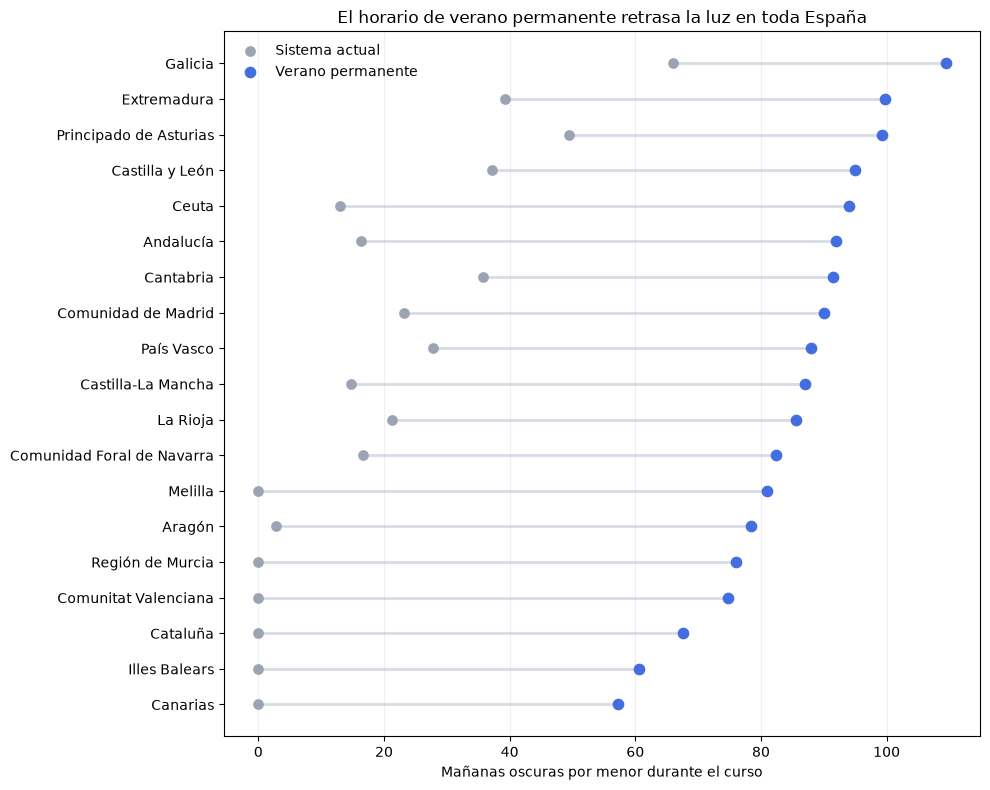

In [10]:
# dibujo una comparación clara de las mañanas oscuras por comunidad
orden = tabla_comunidades.sort_values("verano_permanente").index
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(orden))
ax.scatter(tabla_comunidades.loc[orden, "actual"], y, color="#9aa4b2", s=45, label="Sistema actual", zorder=3)
ax.scatter(tabla_comunidades.loc[orden, "verano_permanente"], y, color=color_principal, s=55, label="Verano permanente", zorder=3)
for posicion, comunidad in enumerate(orden):
    ax.plot(
        [tabla_comunidades.loc[comunidad, "actual"], tabla_comunidades.loc[comunidad, "verano_permanente"]],
        [posicion, posicion], color="#d7dce5", linewidth=2, zorder=1
    )
ax.set_yticks(y, orden)
ax.set_xlabel("Mañanas oscuras por menor durante el curso")
ax.set_title("El horario de verano permanente retrasa la luz en toda España")
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ruta_graficos / "comparacion_comunidades.svg", bbox_inches="tight")
plt.show()


In [11]:
# identifico los extremos municipales del escenario central
extremos = (
    resultados_municipios[
        (resultados_municipios["salida"] == "08:30")
        & (resultados_municipios["escenario"] == "verano_permanente")
    ]
    .sort_values(["dias_oscuros", "poblacion_5_17"], ascending=[False, False])
    [["municipio", "provincia", "comunidad", "poblacion_5_17", "dias_oscuros"]]
)
extremos.head(20)


,municipio,provincia,comunidad,poblacion_5_17,dias_oscuros
19339,Cee,"Coruña, A",Galicia,865,113
19456,Fisterra,"Coruña, A",Galicia,393,113
19591,Muxía,"Coruña, A",Galicia,305,113
19375,Corcubión,"Coruña, A",Galicia,131,113
19771,Ribeira,"Coruña, A",Galicia,3205,112
19753,Porto do Son,"Coruña, A",Galicia,919,112
19717,"Pobra do Caramiñal, A","Coruña, A",Galicia,906,112
19600,Muros,"Coruña, A",Galicia,679,112
19942,Vimianzo,"Coruña, A",Galicia,525,112
19726,Ponteceso,"Coruña, A",Galicia,453,112


## 6. Comprobación de sensibilidad

La hora de salida es la decisión que más puede cambiar la cifra. Comparo las tres para evitar que el titular dependa de un único supuesto. También separo la cantidad de menores afectados al menos una mañana de la suma de exposiciones durante todo el curso.


In [12]:
# preparo una tabla de sensibilidad fácil de leer
sensibilidad = resumen_escenarios.pivot(index="salida", columns="escenario", values="media_dias_por_menor")
sensibilidad.round(1)


escenario,actual,invierno_permanente,verano_permanente
salida,,,
08:00,69.0,48.4,113.5
08:30,15.4,12.3,83.0
09:00,0.4,0.4,48.4


In [13]:
# muestro cuánto añade el verano permanente respecto al sistema actual
aumento = sensibilidad["verano_permanente"] - sensibilidad["actual"]
aumento.rename("mañanas_adicionales_por_menor").round(1)


salida
08:00    44.5
08:30    67.5
09:00    48.0
Name: mañanas_adicionales_por_menor, dtype: float64

## 7. Conclusión y limitaciones

Este EDA responde cuánto cambiaría la exposición a la oscuridad matinal bajo tres relojes, dadas unas horas de salida explícitas. La comparación territorial se apoya en población oficial y posición municipal, pero no observa cada trayecto.

### Qué puedo afirmar

- el horario de verano permanente retrasa una hora el amanecer invernal respecto al horario de invierno;
- el efecto es desigual y se concentra más en el oeste y el norte;
- el tamaño del resultado depende mucho de la hora a la que el menor sale de casa;
- el sistema actual evita parte de las mañanas oscuras al atrasar el reloj en otoño.

### Qué no puedo afirmar

- no conozco el horario ni el trayecto individual de cada menor;
- población de 5 a 17 años no es exactamente alumnado matriculado;
- los calendarios autonómicos y locales pueden restar varias mañanas;
- una mañana oscura no equivale por sí sola a un accidente ni permite trasladar a España el riesgo estimado en Estados Unidos;
- el centroide municipal aproxima la luz del municipio, no la puerta de cada vivienda o colegio.

La cifra principal debe presentarse siempre como **escenario**. La tabla de sensibilidad es parte del resultado, no una nota secundaria.


## Fuentes

- Instituto Nacional de Estadística, tabla nacional 68542: *Población por sexo y edad (año a año)*, Censo anual de población 2021-2025.
- Instituto Geográfico Nacional, servicio SIGNA: *Centroides de municipios*.
- NOAA Global Monitoring Laboratory: ecuaciones de posición solar y amanecer.
- Calendarios oficiales y recopilación del curso 2026-2027 utilizada para fijar el intervalo común. Los días locales no se incorporan.
